# 07 · Baseline check: do the features work, and are they honest?

This is **not** the final model. It's a quick health check of the feature tables:
1. Train a standard model (**LightGBM**) on the training period, test on the newest period.
2. Measure **AUC**: how well the model ranks risky cases above safe ones. 0.5 = coin flip, 1.0 = perfect.
   Real-world operations data usually lands around 0.70–0.85.
3. See which features matter most.
4. **Leakage demo:** add one "future" column on purpose and watch the score jump to something too good to be true.

**Rule of thumb:** if AUC is above ~0.90 on messy real data, suspect leakage before celebrating.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED, INTERIM, REPORTS, FIG = (ROOT / "data/processed", ROOT / "data/interim",
                                     ROOT / "reports", ROOT / "reports/figures")

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12,
})

## A helper that trains and evaluates
- `fit` learns from the training rows.
- `predict_proba` gives each test row a risk score between 0 and 1.
- **Precision in the top 10%**: if a manager only reviews the 10% riskiest cases, what share of them really go wrong? Easy to explain to non-technical people.

In [4]:
def train_and_score(X, y, is_train, label):
    # Settings are deliberately "cautious" (small trees, at least 200 rows per leaf, extra penalty)
    # so the model can't memorise the training period. With LightGBM's defaults the test score was lower.
    model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=200,
                               reg_lambda=5, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=42, verbose=-1)
    model.fit(X[is_train], y[is_train])
    p_test = model.predict_proba(X[~is_train])[:, 1]
    p_train = model.predict_proba(X[is_train])[:, 1]
    y_test = y[~is_train].values
    top10 = p_test >= np.quantile(p_test, 0.90)
    result = {
        "model": label,
        "train_AUC": round(float(roc_auc_score(y[is_train], p_train)), 3),
        "test_AUC": round(float(roc_auc_score(y_test, p_test)), 3),
        "base_rate_test": round(float(y_test.mean()), 3),
        "precision_top10%": round(float(y_test[top10].mean()), 3),
    }
    return model, result

def plot_importance(model, title, fname, top=15):
    imp = pd.Series(model.booster_.feature_importance("gain"), index=model.feature_name_)
    imp = (imp / imp.sum()).sort_values().tail(top)
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.barh(imp.index, imp.values * 100, color=BLUE, height=0.65)
    ax.set_title(title)
    ax.set_xlabel("share of total importance (%)")
    ax.grid(axis="y", visible=False)
    fig.savefig(FIG / fname, dpi=120, bbox_inches="tight")
    plt.show()

results = []

## Part 1: Incidents (predict SLA breach at ticket opening)

In [5]:
inc = pd.read_parquet(PROCESSED / "incidents_features.parquet")
X_inc = inc.drop(columns=["number", "opened_at", "split", "breached"])
y_inc = inc["breached"]
tr_inc = inc["split"] == "train"
print("Features:", X_inc.shape[1], "  Train:", tr_inc.sum(), "  Test:", (~tr_inc).sum())

m_inc, r = train_and_score(X_inc, y_inc, tr_inc, "Incidents: honest features")
results.append(r)
r

Features: 33   Train: 19715   Test: 4929


{'model': 'Incidents: honest features',
 'train_AUC': 0.92,
 'test_AUC': 0.771,
 'base_rate_test': 0.225,
 'precision_top10%': 0.517}

**How to read this:**
- `test_AUC` is the real score, on tickets the model never saw, from a later period.
- `train_AUC` is higher. Some gap is normal; a huge gap means the model memorised the training data (**overfitting**).
- `precision_top10%` vs `base_rate_test`: among the 10% tickets the model flags as riskiest, the breach rate is several times the average. That's useful for prioritising.

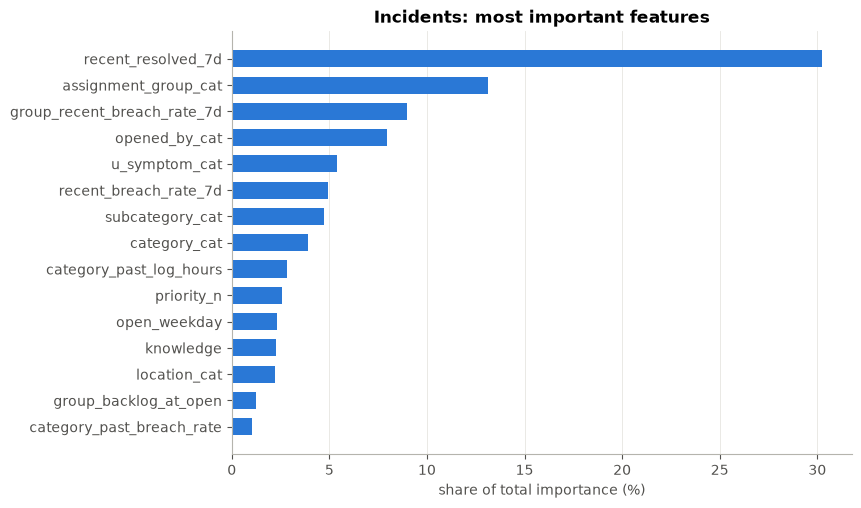

In [6]:
plot_importance(m_inc, "Incidents: most important features", "baseline_importance_incidents.png")

### Leakage demo (incidents)
Now we add `final_reassignment_count`, known only **after** the ticket is finished, and retrain.

In [7]:
clean_inc = pd.read_parquet(INTERIM / "incidents_clean.parquet")[["number", "final_reassignment_count", "final_sys_mod_count"]]
X_leak = X_inc.join(inc[["number"]].merge(clean_inc, on="number", how="left").drop(columns="number"))
_, r = train_and_score(X_leak, y_inc, tr_inc, "Incidents: WITH LEAKY columns (wrong!)")
results.append(r)
r

{'model': 'Incidents: WITH LEAKY columns (wrong!)',
 'train_AUC': 0.978,
 'test_AUC': 0.928,
 'base_rate_test': 0.225,
 'precision_top10%': 0.909}

The score jumps. It looks amazing, but this model is useless in real life: when a ticket is opened, nobody knows how many times it *will* be reassigned.
**This is why we separated `final_...` columns in notebook 02.**

## Part 2: Sales (predict late delivery at order approval)

In [8]:
sales = pd.read_parquet(PROCESSED / "sales_orders_features.parquet")
X_s = sales.drop(columns=["order_id", "purchased_at", "approved_at", "split", "late"])
y_s = sales["late"]
tr_s = sales["split"] == "train"
print("Features:", X_s.shape[1], "  Train:", tr_s.sum(), "  Test:", (~tr_s).sum())

m_s, r = train_and_score(X_s, y_s, tr_s, "Sales: honest features")
results.append(r)
r

Features: 41   Train: 76815   Test: 19204


{'model': 'Sales: honest features',
 'train_AUC': 0.836,
 'test_AUC': 0.715,
 'base_rate_test': 0.053,
 'precision_top10%': 0.103}

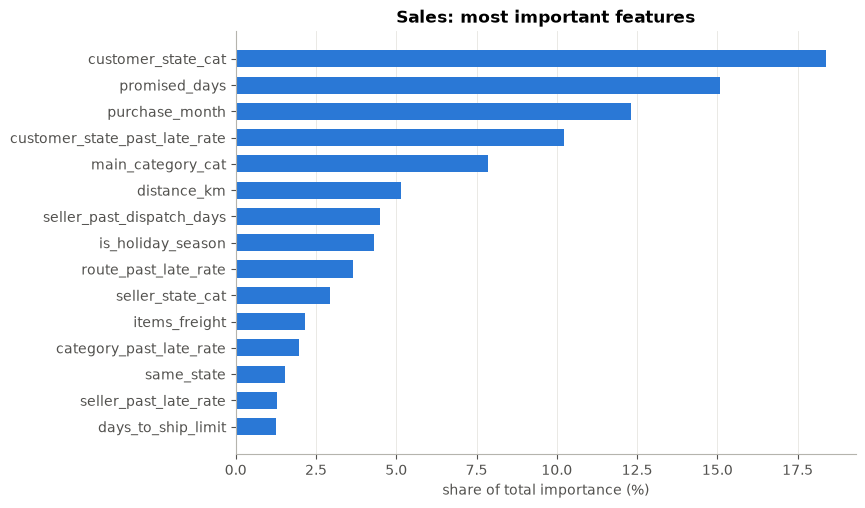

In [9]:
plot_importance(m_s, "Sales: most important features", "baseline_importance_sales.png")

### Leakage demo (sales)
We add the actual days from approval to carrier pickup, known only once the seller ships.

In [10]:
clean_s = pd.read_parquet(INTERIM / "sales_orders_clean.parquet")[["order_id", "carrier_at", "approved_at"]]
clean_s["actual_dispatch_days"] = (clean_s["carrier_at"] - clean_s["approved_at"]).dt.total_seconds() / 86400
X_leak = X_s.join(sales[["order_id"]].merge(clean_s[["order_id", "actual_dispatch_days"]], on="order_id", how="left").drop(columns="order_id"))
_, r = train_and_score(X_leak, y_s, tr_s, "Sales: WITH LEAKY column (wrong!)")
results.append(r)
r

{'model': 'Sales: WITH LEAKY column (wrong!)',
 'train_AUC': 0.868,
 'test_AUC': 0.83,
 'base_rate_test': 0.053,
 'precision_top10%': 0.232}

## Summary

In [11]:
summary = pd.DataFrame(results)
summary.to_csv(REPORTS / "baseline_results.csv", index=False)
summary

,model,train_AUC,test_AUC,base_rate_test,precision_top10%
0,Incidents: honest features,0.920,0.771,0.225,0.517
1,Incidents: WITH LEAKY columns (wrong!),0.978,0.928,0.225,0.909
2,Sales: honest features,0.836,0.715,0.053,0.103
3,Sales: WITH LEAKY column (wrong!),0.868,0.830,0.053,0.232


### What this tells you
- Both feature tables **work**: test AUC is about **0.77 for incidents** and **0.72 for sales**, well above chance (0.5) and in the normal range for real operations data.
- The model's top-10% riskiest tickets breach about **2.3× more often** than average, and its top-10% riskiest orders are late about **2× more often**. That's the basis for "prioritise these first".
- The leaky versions score higher, which is exactly why you must never trust a high score without checking *when* each feature is known.
- The **feature dictionaries** in `reports/` are your written proof that every feature is known at prediction time.